In [1]:
import nibabel as nb 
import numpy as np 
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from Functional_Fusion.reliability import decompose_subj_group
import Functional_Fusion.util as ut
from scipy.stats import ttest_1samp

from scripts import decomposing_variances
from scripts import make_atlas
#from scripts import bold_normalization 
import Functional_Fusion.dataset as ds
import Functional_Fusion.atlas_map as am

/var/folders/91/7fqn4cp541g41hf5rkxmsnhh0000gn/T/ipykernel_9006/2684524075.py:3: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


In [35]:
# make .tsv file that splits hands for variance decomposition 

import numpy as np
import pandas as pd
import Functional_Fusion.dataset as ds
from Functional_Fusion.reliability import decompose_subj_group

base_dir = '/Volumes/diedrichsen_data$/data/FunctionalFusion_new'
out_file = 'var_decomp_split_hand.tsv'
atlases = ['MNISymOlive1', 'MNISymCereb2']
hands = {'right': [1, 2, 3, 4, 13, 14, 15, 16],
         'left':  [5, 6, 7, 8, 9, 10, 11, 12],
         'both':  list(range(1, 17))}

shared = {                      # common label: (Olive7T name, Language name)
    'action observation': ('action_observation', 'actobserv'),
    'demand grid':        ('demand_grid_easy_diff', 'dmndgrid'),
    'movie':              ('movie', 'movie'),
    'rest':               ('rest', 'rest'),
    'spatial navigation': ('spatial_navigation', 'spatialnav'),
    'verb generation':    ('verb_generation', 'vrbgen'),
}
finger = {'rest':            ('rest', 'rest'),
          'finger sequence': ('finger_sequence_surprise', 'fingr')}
task_sets = {'all tasks': None,                 # None = keep every task
             'shared tasks': shared,
             'finger sequence vs rest': finger}

olive = ds.DataSetNative(base_dir + '/Olive')
lang = ds.get_dataset_class(base_dir, 'Language')
subj_o = olive.get_participants().participant_id.tolist()
subj_l = lang.get_participants().participant_id.tolist()

rows = []
for atlas in atlases:
    data_o, info_o = olive.get_data(space=atlas, ses_id='ses-s1', type='CondRun')
    data_l, info_l = lang.get_data(space=atlas, ses_id='ses-localizerfm', type='CondRun')
    data_o = np.nan_to_num(data_o)
    data_l = np.nan_to_num(data_l)

    for tasks, pairs in task_sets.items():
        if pairs is None:
            sel_o = np.ones(len(info_o), dtype=bool)
            sel_l = np.ones(len(info_l), dtype=bool)
        else:
            sel_o = info_o.task_code.isin([v[0] for v in pairs.values()]).values
            sel_l = info_l.task_code.isin([v[1] for v in pairs.values()]).values

        # ---- Olive7T: right, left and both hands ----
        for hand, runs in hands.items():
            keep = sel_o & info_o.run.isin(runs).values
            data = data_o[:, keep, :]
            cond_vec = pd.factorize(info_o.task_code[keep])[0] + 1
            part_vec = info_o.run.values[keep]
            print(atlas, tasks, 'Olive7T', hand, data.shape,
                  len(np.unique(cond_vec)), 'tasks,', len(np.unique(part_vec)), 'runs')

            var_decomp = decompose_subj_group(data, cond_vec, part_vec,
                                              separate='subject_wise', subtract_mean=True)
            var_norm = var_decomp / var_decomp.sum(axis=1, keepdims=True)

            for s, v in zip(subj_o, var_norm):
                rows.append({'group': v[0], 'individual': v[1], 'noise': v[2],
                             'subj_id': s, 'hand': hand, 'tasks': tasks,
                             'dataset': 'Olive7T', 'atlas': atlas})

        # ---- Language: all runs ----
        data = data_l[:, sel_l, :]
        cond_vec = pd.factorize(info_l.task_code[sel_l])[0] + 1
        part_vec = info_l.run.values[sel_l]
        print(atlas, tasks, 'Language', data.shape,
              len(np.unique(cond_vec)), 'tasks,', len(np.unique(part_vec)), 'runs')

        var_decomp = decompose_subj_group(data, cond_vec, part_vec,
                                          separate='subject_wise', subtract_mean=True)
        var_norm = var_decomp / var_decomp.sum(axis=1, keepdims=True)

        for s, v in zip(subj_l, var_norm):
            rows.append({'group': v[0], 'individual': v[1], 'noise': v[2],
                         'subj_id': s, 'hand': 'none', 'tasks': tasks,
                         'dataset': 'Language', 'atlas': atlas})

D = pd.DataFrame(rows)
D.to_csv(out_file, sep='\t', index=False)

MNISymOlive1 all tasks Olive7T right (6, 104, 1448) 13 tasks, 8 runs
MNISymOlive1 all tasks Olive7T left (6, 104, 1448) 13 tasks, 8 runs
MNISymOlive1 all tasks Olive7T both (6, 208, 1448) 13 tasks, 16 runs
MNISymOlive1 all tasks Language (17, 144, 1448) 14 tasks, 8 runs
MNISymOlive1 shared tasks Olive7T right (6, 48, 1448) 6 tasks, 8 runs
MNISymOlive1 shared tasks Olive7T left (6, 48, 1448) 6 tasks, 8 runs
MNISymOlive1 shared tasks Olive7T both (6, 96, 1448) 6 tasks, 16 runs
MNISymOlive1 shared tasks Language (17, 64, 1448) 6 tasks, 8 runs
MNISymOlive1 finger sequence vs rest Olive7T right (6, 16, 1448) 2 tasks, 8 runs
MNISymOlive1 finger sequence vs rest Olive7T left (6, 16, 1448) 2 tasks, 8 runs
MNISymOlive1 finger sequence vs rest Olive7T both (6, 32, 1448) 2 tasks, 16 runs
MNISymOlive1 finger sequence vs rest Language (17, 16, 1448) 2 tasks, 8 runs
MNISymCereb2 all tasks Olive7T right (6, 104, 18290) 13 tasks, 8 runs
MNISymCereb2 all tasks Olive7T left (6, 104, 18290) 13 tasks, 8 r

In [41]:
# Set Figure style to talk on black background

rc = {'axes.facecolor': 'white',
 'axes.edgecolor': 'black',
 'axes.grid': False,
 'axes.axisbelow': 'line',
 'axes.labelcolor': 'black',
 'figure.facecolor': 'white',
 'text.color': 'black',
 'xtick.color': 'black',
 'ytick.color': 'black',
 'xtick.direction': 'out',
 'ytick.direction': 'out',
 'patch.edgecolor': 'black',
 'patch.force_edgecolor': False,
 'image.cmap': 'viridis',
 'xtick.bottom': True,
 'xtick.top': False,
 'ytick.left': True,
 'ytick.right': False,
 'axes.spines.left': True,
 'axes.spines.bottom': True,
 'axes.spines.right': False,
 'axes.spines.top': False}
sns.set_style(rc=rc)



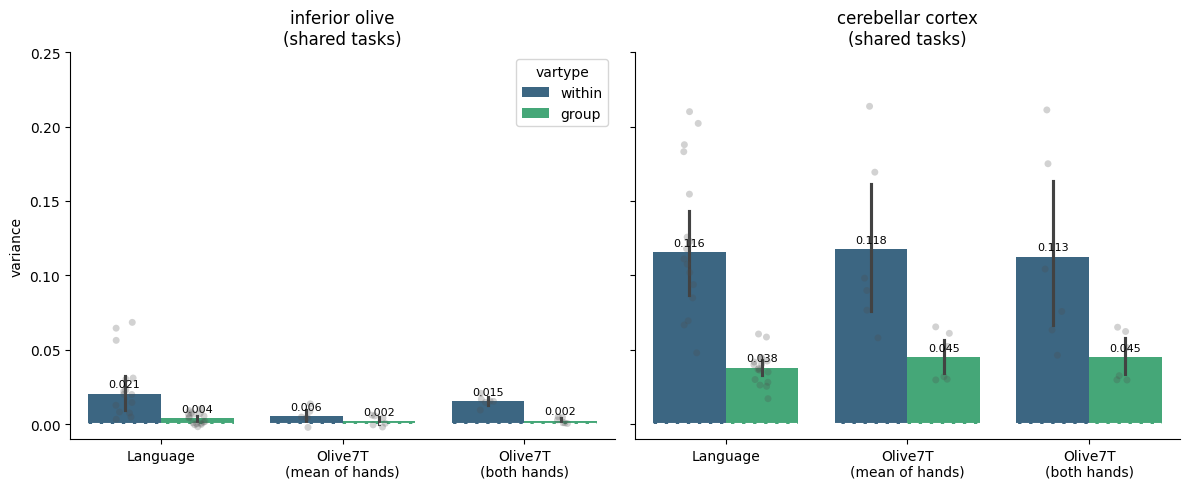

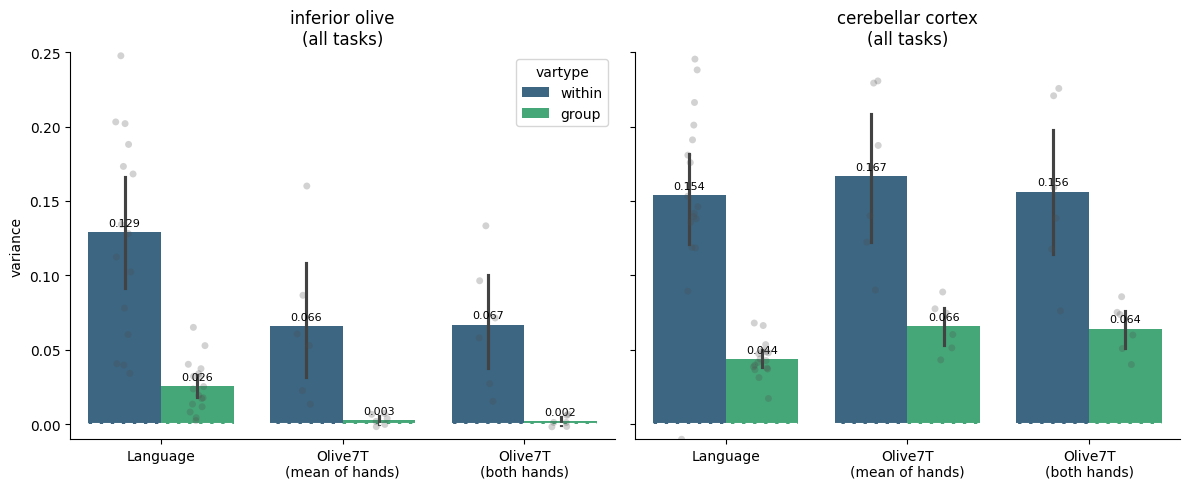

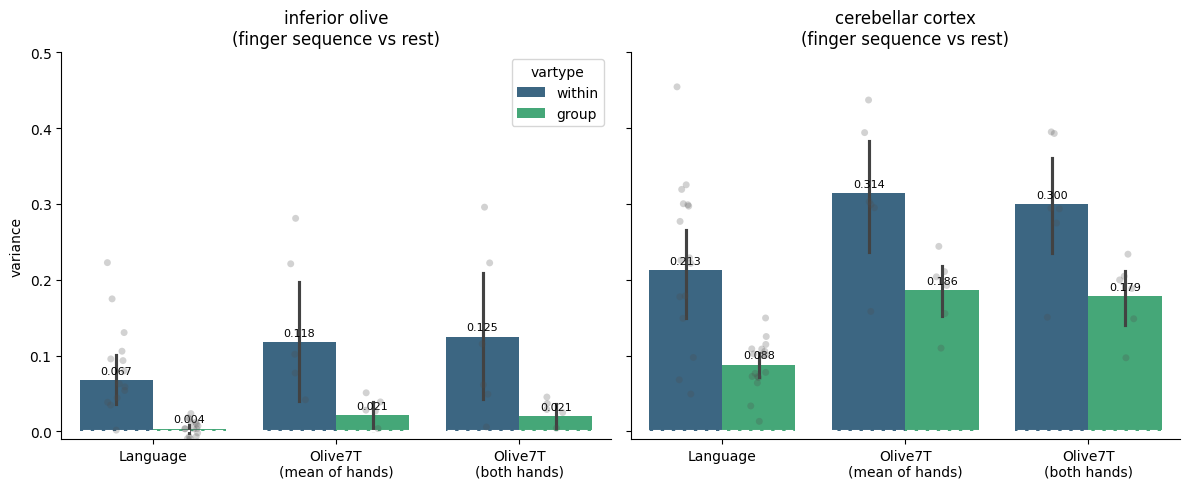

In [42]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

pal = [[0.3,0.3,0.3], [0.3,0.3,0.3]] #for black bgd

D = pd.read_csv('var_decomp_split_hand.tsv', sep='\t')
D['within'] = D.group + D.individual

mean_h = (D[(D.dataset == 'Olive7T') & D.hand.isin(['right', 'left'])]
          .groupby(['atlas', 'tasks', 'subj_id'], as_index=False)[['within', 'group']].mean())
mean_h['analysis'] = 'Olive7T mean'

both_h = D[(D.dataset == 'Olive7T') & (D.hand == 'both')][['atlas', 'tasks', 'subj_id', 'within', 'group']].copy()
both_h['analysis'] = 'Olive7T both'

lang = D[D.dataset == 'Language'][['atlas', 'tasks', 'subj_id', 'within', 'group']].copy()
lang['analysis'] = 'Language'

T = (pd.concat([lang, mean_h, both_h], ignore_index=True)
       .melt(id_vars=['atlas', 'tasks', 'subj_id', 'analysis'],
             value_vars=['within', 'group'],
             var_name='vartype', value_name='variance'))

atlases = {'MNISymOlive1': 'inferior olive',
           'MNISymCereb2': 'cerebellar cortex'}
task_sets = {'shared tasks': 0.25,                 # task set: upper y-limit
             'all tasks': 0.25,
             'finger sequence vs rest': 0.5}
order = ['Language', 'Olive7T mean', 'Olive7T both']
tick_labels = ['Language', 'Olive7T\n(mean of hands)', 'Olive7T\n(both hands)']

for tasks, ymax in task_sets.items():
    fig, axes = plt.subplots(1, len(atlases), figsize=(6 * len(atlases), 5), sharey=True)
    for i, (ax, (atlas, title)) in enumerate(zip(np.atleast_1d(axes), atlases.items())):
        X = T[(T.atlas == atlas) & (T.tasks == tasks)]
        sns.barplot(data=X, x='analysis', y='variance', hue='vartype',
                    order=order,
                    hue_order=['within', 'group'], palette='viridis', ax=ax)
        for c in ax.containers:
            ax.bar_label(c, fmt='%.3f', fontsize=8, padding=3)
        sns.stripplot(data=X, x='analysis', y='variance', hue='vartype',
                      order=order,
                      hue_order=['within', 'group'],
                      palette=pal, alpha=0.25, jitter=0.1,
                      dodge=True, legend=False, ax=ax)
        ax.axhline(0, color='white', linestyle='--')
        ax.set_ylim(-0.01, ymax)
        ax.set_title(f'{title}\n({tasks})')
        ax.set_xlabel('')
        ax.set_xticks(range(len(order)))
        ax.set_xticklabels(tick_labels)
        if i > 0 and ax.get_legend() is not None:
            ax.get_legend().remove()           
    plt.tight_layout()
    plt.show()


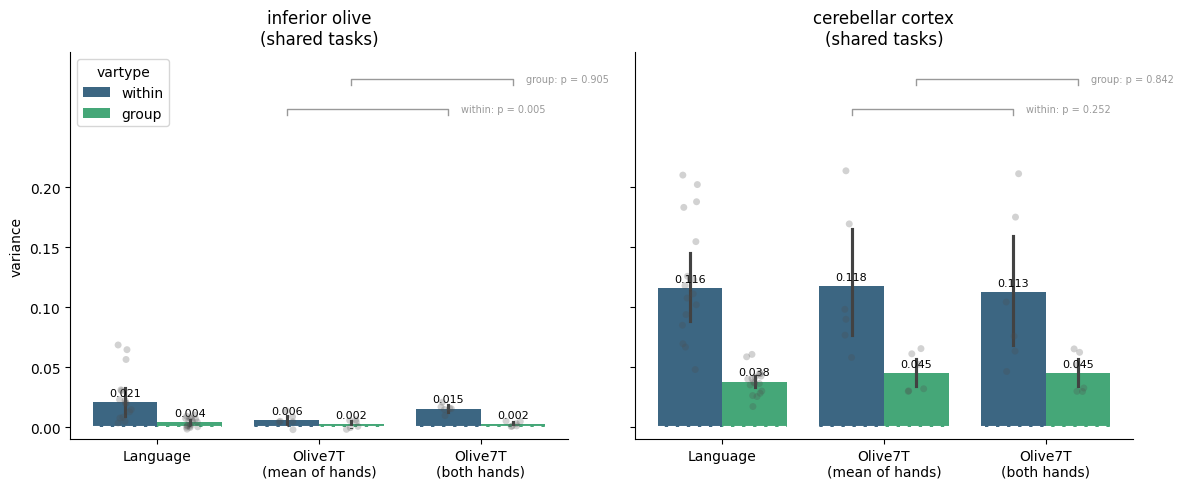

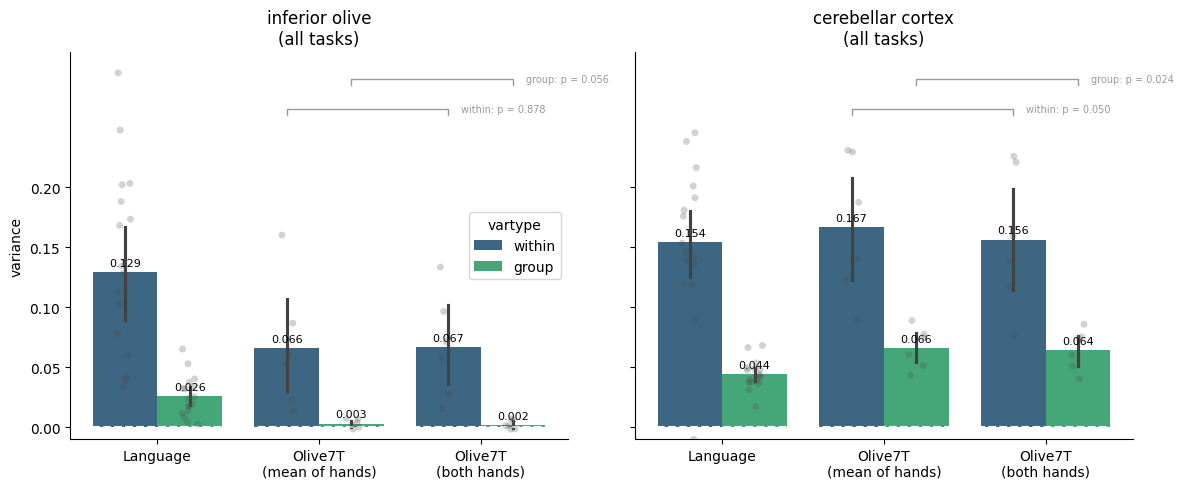

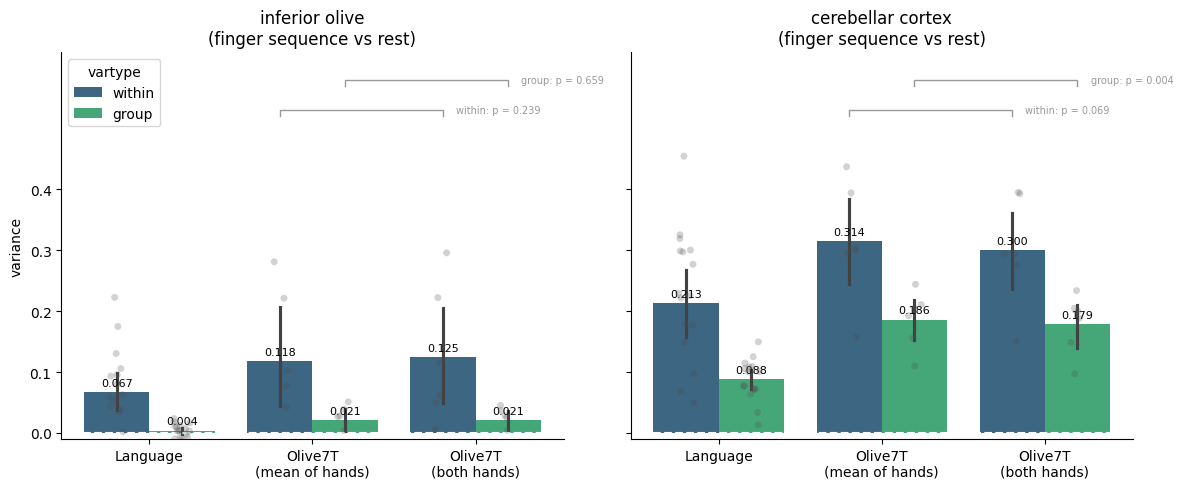

                  tasks        atlas vartype  mean_of_hands  both_hands  mean_diff n_higher       t      p
           shared tasks MNISymOlive1  within         0.0056      0.0154    -0.0098      0/6 -4.8700 0.0046
           shared tasks MNISymOlive1   group         0.0023      0.0025    -0.0001      3/6 -0.1254 0.9051
           shared tasks MNISymCereb2  within         0.1176      0.1126     0.0050      4/6  1.2947 0.2520
           shared tasks MNISymCereb2   group         0.0451      0.0452    -0.0001      4/6 -0.2098 0.8421
              all tasks MNISymOlive1  within         0.0660      0.0669    -0.0009      1/6 -0.1619 0.8777
              all tasks MNISymOlive1   group         0.0030      0.0019     0.0010      5/6  2.4809 0.0558
              all tasks MNISymCereb2  within         0.1666      0.1563     0.0103      6/6  2.5731 0.0498
              all tasks MNISymCereb2   group         0.0659      0.0642     0.0017      6/6  3.2147 0.0236
finger sequence vs rest MNISymOlive1 

In [43]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

pal = [[0.3,0.3,0.3], [0.3,0.3,0.3]] #for black bgd

D = pd.read_csv('var_decomp_split_hand.tsv', sep='\t')
D['within'] = D.group + D.individual

# ---- the three groups ----
mean_h = (D[(D.dataset == 'Olive7T') & D.hand.isin(['right', 'left'])]
          .groupby(['atlas', 'tasks', 'subj_id'], as_index=False)[['within', 'group']].mean())
mean_h['analysis'] = 'Olive7T mean'

both_h = D[(D.dataset == 'Olive7T') & (D.hand == 'both')][['atlas', 'tasks', 'subj_id', 'within', 'group']].copy()
both_h['analysis'] = 'Olive7T both'

lang = D[D.dataset == 'Language'][['atlas', 'tasks', 'subj_id', 'within', 'group']].copy()
lang['analysis'] = 'Language'

T = (pd.concat([lang, mean_h, both_h], ignore_index=True)
       .melt(id_vars=['atlas', 'tasks', 'subj_id', 'analysis'],
             value_vars=['within', 'group'],
             var_name='vartype', value_name='variance'))

# ---- plot settings ----
atlases = {'MNISymOlive1': 'inferior olive',
           'MNISymCereb2': 'cerebellar cortex'}
task_sets = {'shared tasks': 0.25,                 # task set: upper y-limit
             'all tasks': 0.25,
             'finger sequence vs rest': 0.5}
order = ['Language', 'Olive7T mean', 'Olive7T both']
tick_labels = ['Language', 'Olive7T\n(mean of hands)', 'Olive7T\n(both hands)']
hue_order = ['within', 'group']
offsets = {'within': -0.2, 'group': 0.2}           # bar positions within each x group


def p_text(p):
    return 'p < .001' if p < 0.001 else f'p = {p:.3f}'


results = []
for tasks, ymax in task_sets.items():
    fig, axes = plt.subplots(1, len(atlases), figsize=(6 * len(atlases), 5), sharey=True)
    for i, (ax, (atlas, title)) in enumerate(zip(np.atleast_1d(axes), atlases.items())):
        X = T[(T.atlas == atlas) & (T.tasks == tasks)]
        sns.barplot(data=X, x='analysis', y='variance', hue='vartype',
                    order=order, hue_order=hue_order, palette='viridis', ax=ax)
        for c in ax.containers:
            ax.bar_label(c, fmt='%.3f', fontsize=8, padding=3)
        sns.stripplot(data=X, x='analysis', y='variance', hue='vartype',
                      order=order, hue_order=hue_order,
                      palette=pal, alpha=0.25, jitter=0.1,
                      dodge=True, legend=False, ax=ax)

        # ---- paired t-test: mean of hands vs both hands ----
        for k, v in enumerate(hue_order):
            w = (X[(X.vartype == v) & X.analysis.isin(['Olive7T mean', 'Olive7T both'])]
                 .pivot(index='subj_id', columns='analysis', values='variance'))
            diff = w['Olive7T mean'] - w['Olive7T both']
            t, p = stats.ttest_rel(w['Olive7T mean'], w['Olive7T both'])
            results.append({'tasks': tasks, 'atlas': atlas, 'vartype': v,
                            'mean_of_hands': w['Olive7T mean'].mean(),
                            'both_hands': w['Olive7T both'].mean(),
                            'mean_diff': diff.mean(),
                            'n_higher': f'{(diff > 0).sum()}/{len(diff)}',
                            't': t, 'p': p})

             # bracket in a reserved strip above the data
            x1 = order.index('Olive7T mean') + offsets[v]
            x2 = order.index('Olive7T both') + offsets[v]
            y = ymax * (1.06 + 0.10 * k)            # within: 1.06 x ymax, group: 1.16 x ymax
            tick = ymax * 0.02
            ax.plot([x1, x1, x2, x2], [y - tick, y, y, y - tick], color='0.6', lw=1)
            ax.text(x2 + 0.08, y, f'{v}: {p_text(p)}',
                    ha='left', va='center', fontsize=7, color='0.6')

        ax.axhline(0, color='white', linestyle='--')
        ax.set_ylim(-0.01, ymax * 1.25)             # extra room at the top for the brackets
        ax.set_yticks([t for t in ax.get_yticks() if 0 <= t <= ymax])   # no ticks in the bracket strip
        ax.set_title(f'{title}\n({tasks})')
        ax.set_xlabel('')
        ax.set_xticks(range(len(order)))
        ax.set_xticklabels(tick_labels)
        if i > 0 and ax.get_legend() is not None:
            ax.get_legend().remove()            # keep the legend only in the first panel
    plt.tight_layout()
    plt.show()

# ---- all test results in one table ----
R = pd.DataFrame(results)
print(R.round(4).to_string(index=False))

---- MNISymOlive1
Olive7T empty rows per subject: [0 0 0 0 0 0]
Language empty rows per subject: [  0   0   0   0   0   0 144   0   0   0   0   0   0 144   0   0   0]
618 of 1448 voxels kept
(6, 48, 618) 6 tasks, 8 partitions
(6, 48, 618) 6 tasks, 8 partitions
(6, 96, 618) 6 tasks, 16 partitions
(17, 64, 618) 6 tasks, 8 partitions
---- MNISymCereb2
Olive7T empty rows per subject: [208   0   0 208 208   0]
Language empty rows per subject: [  0   0   0   0   0   0 144   0   0   0   0   0   0 144 144 144   0]
17209 of 18290 voxels kept
(6, 48, 17209) 6 tasks, 8 partitions
(6, 48, 17209) 6 tasks, 8 partitions
(6, 96, 17209) 6 tasks, 16 partitions
(17, 64, 17209) 6 tasks, 8 partitions


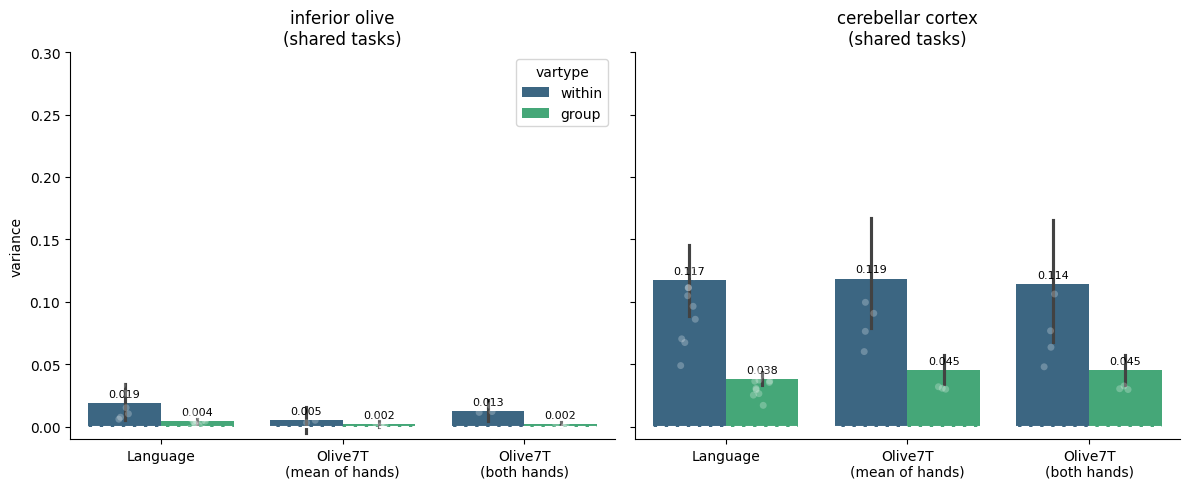

In [46]:
#shared tasks: Language vs Olive7T (mean of hands) vs Olive7T (both hands), olive and cerebellar cortex

pal = [[1,1,1], [1,1,1]] #for black bgd

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import Functional_Fusion.dataset as ds
from Functional_Fusion.reliability import decompose_subj_group

base_dir = '/Volumes/diedrichsen_data$/data/FunctionalFusion_new'
atlases = {'MNISymOlive1': 'inferior olive',
           'MNISymCereb2': 'cerebellar cortex'}          
hands = {'right': [1, 2, 3, 4, 13, 14, 15, 16],
         'left':  [5, 6, 7, 8, 9, 10, 11, 12]}
pairs = {                      # common label: (Olive7T name, Language name)
    'action observation': ('action_observation', 'actobserv'),
    'demand grid':        ('demand_grid_easy_diff', 'dmndgrid'),
    'movie':              ('movie', 'movie'),
    'rest':               ('rest', 'rest'),
    'spatial navigation': ('spatial_navigation', 'spatialnav'),
    'verb generation':    ('verb_generation', 'vrbgen'),
    #'finger sequence':    ('finger_sequence_surprise', 'fingr'),
}
task_set = 'shared tasks'    
olive_tasks = [v[0] for v in pairs.values()]
lang_tasks = [v[1] for v in pairs.values()]


def decompose(data, info, keep, part_col):
    """Subject-wise decomposition on the selected rows -> shares per subject"""
    cond_vec = pd.factorize(info.task_code[keep])[0] + 1
    part_vec = info[part_col].values[keep]
    print(data[:, keep].shape, len(np.unique(cond_vec)), 'tasks,',
          len(np.unique(part_vec)), 'partitions')
    v = decompose_subj_group(data[:, keep, :], cond_vec, part_vec,
                             separate='subject_wise', subtract_mean=True)
    return v / v.sum(axis=1, keepdims=True)


olive = ds.DataSetNative(base_dir + '/Olive')
lang = ds.get_dataset_class(base_dir, 'Language')
subj_o = olive.get_participants().participant_id.tolist()
subj_l = lang.get_participants().participant_id.tolist()

rows = []
for atlas in atlases:
    print('----', atlas)
    # ---- load both datasets ----
    data_o, info_o = olive.get_data(space=atlas, ses_id='ses-s1', type='CondRun')
    data_l, info_l = lang.get_data(space=atlas, ses_id='ses-localizerfm', type='CondRun')
    print('Olive7T empty rows per subject:', np.isnan(data_o).any(axis=2).sum(axis=1))
    print('Language empty rows per subject:', np.isnan(data_l).any(axis=2).sum(axis=1))

    # ---- empty voxels ----
    #data_o = np.nan_to_num(data_o)
    #data_l = np.nan_to_num(data_l)


    valid = ~np.isnan(data_o).any(axis=(0, 1)) & ~np.isnan(data_l).any(axis=(0, 1))
    print(valid.sum(), 'of', len(valid), 'voxels kept')
    data_o = data_o[:, :, valid]
    data_l = data_l[:, :, valid]
    

    # ---- Olive7T: shared tasks ----
    shared_o = info_o.task_code.isin(olive_tasks).values
    # mean of hands: each hand separately, then averaged
    v_mean = np.mean([decompose(data_o, info_o, shared_o & info_o.run.isin(runs).values, 'run')
                      for runs in hands.values()], axis=0)
    # both hands: all 16 runs in one decomposition
    v_both = decompose(data_o, info_o, shared_o, 'run')

    for label, V in [('Olive7T mean', v_mean), ('Olive7T both', v_both)]:
        for s, v in zip(subj_o, V):
            rows.append({'atlas': atlas, 'dataset': label, 'subj_id': s,
                         'group': v[0], 'individual': v[1], 'noise': v[2]})

    # ---- Language: shared tasks ----
    shared_l = info_l.task_code.isin(lang_tasks).values
    for s, v in zip(subj_l, decompose(data_l, info_l, shared_l, 'run')):
        rows.append({'atlas': atlas, 'dataset': 'Language', 'subj_id': s,
                     'group': v[0], 'individual': v[1], 'noise': v[2]})

D_sh = pd.DataFrame(rows)
D_sh['within'] = D_sh.group + D_sh.individual
T_sh = D_sh.melt(id_vars=['dataset', 'atlas', 'subj_id'],
                 value_vars=['group', 'within'],
                 var_name='vartype', value_name='variance')

# ---- plot: one panel per atlas ----
order = ['Language', 'Olive7T mean', 'Olive7T both']
tick_labels = ['Language', 'Olive7T\n(mean of hands)', 'Olive7T\n(both hands)']

fig, axes = plt.subplots(1, len(atlases), figsize=(6 * len(atlases), 5), sharey=True)
for ax, (atlas, title) in zip(np.atleast_1d(axes), atlases.items()):
    X = T_sh[T_sh.atlas == atlas]
    sns.barplot(data=X, x='dataset', y='variance', hue='vartype',
                order=order,
                hue_order=['within', 'group'], palette='viridis', ax=ax)
    for c in ax.containers:
        ax.bar_label(c, fmt='%.3f', fontsize=8, padding=3)
    sns.stripplot(data=X, x='dataset', y='variance', hue='vartype',
                  order=order,
                  hue_order=['within', 'group'],
                  palette=pal, alpha=0.25, jitter=0.1,
                  dodge=True, legend=False, ax=ax)
    ax.axhline(0, color='white', linestyle='--')
    ax.set_ylim(-0.01, 0.3)
    ax.set_title(f'{title}\n({task_set})')
    ax.set_xlabel('')
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(tick_labels)
    if ax is not np.atleast_1d(axes)[0] and ax.get_legend() is not None:
        ax.get_legend().remove()            # keep the legend only in the first panel

plt.tight_layout()
plt.show()

---- MNISymOlive1
618 of 1448 voxels kept
(6, 104, 618) 13 tasks, 8 partitions
(6, 104, 618) 13 tasks, 8 partitions
(6, 208, 618) 13 tasks, 16 partitions
(17, 144, 618) 14 tasks, 8 partitions
---- MNISymCereb2
17209 of 18290 voxels kept
(6, 104, 17209) 13 tasks, 8 partitions
(6, 104, 17209) 13 tasks, 8 partitions
(6, 208, 17209) 13 tasks, 16 partitions
(17, 144, 17209) 14 tasks, 8 partitions


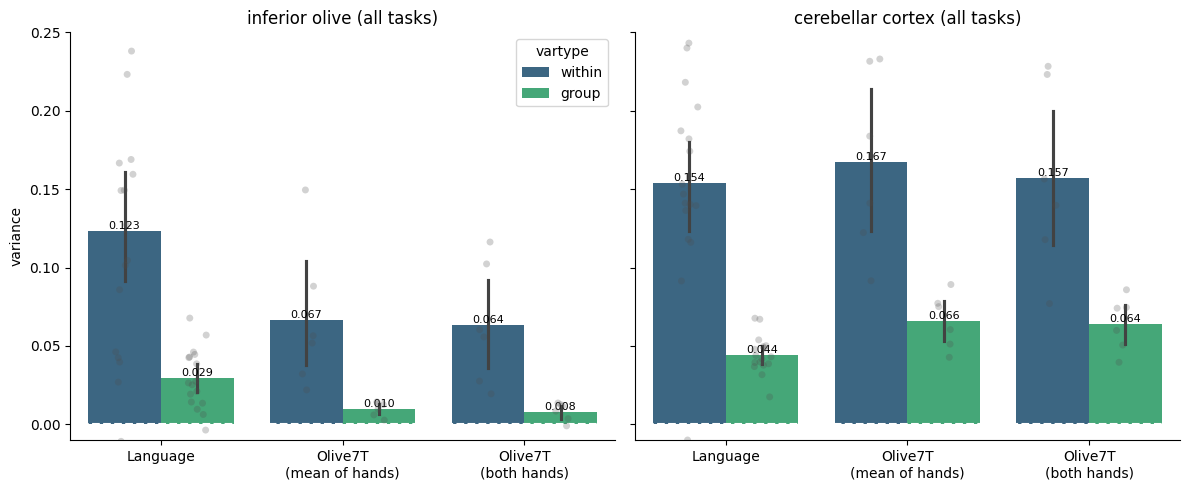

<Figure size 640x480 with 0 Axes>

In [44]:
#all tasks, Olive with mean hands vs Language — olive and cerebellar cortex side by side

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import Functional_Fusion.dataset as ds
from Functional_Fusion.reliability import decompose_subj_group

base_dir = '/Volumes/diedrichsen_data$/data/FunctionalFusion_new'
atlases = {'MNISymOlive1': 'inferior olive',
           'MNISymCereb2': 'cerebellar cortex'}          # atlas: panel title
hands = {'right': [1, 2, 3, 4, 13, 14, 15, 16],
         'left':  [5, 6, 7, 8, 9, 10, 11, 12]}


def decompose(data, info, keep, part_col):
    """Subject-wise decomposition on the selected rows -> shares per subject"""
    cond_vec = pd.factorize(info.task_code[keep])[0] + 1
    #labels = (info.task_code.astype(str) + '_' + info.cond_code.astype(str)).values[keep]
    #cond_vec = pd.factorize(labels)[0] + 1
    part_vec = info[part_col].values[keep]
    print(data[:, keep].shape, len(np.unique(cond_vec)), 'tasks,',
          len(np.unique(part_vec)), 'partitions')
    v = decompose_subj_group(data[:, keep, :], cond_vec, part_vec,
                             separate='subject_wise', subtract_mean=True)
    return v / v.sum(axis=1, keepdims=True)


olive = ds.DataSetNative(base_dir + '/Olive')
lang = ds.get_dataset_class(base_dir, 'Language')
subj_o = olive.get_participants().participant_id.tolist()
subj_l = lang.get_participants().participant_id.tolist()

rows = []
for atlas in atlases:
    print('----', atlas)
    # ---- load both datasets ----
    data_o, info_o = olive.get_data(space=atlas, ses_id='ses-s1', type='CondRun')
    data_l, info_l = lang.get_data(space=atlas, ses_id='ses-localizerfm', type='CondRun')

    # ---- empty voxels ----
    #data_o = np.nan_to_num(data_o)
    #data_l = np.nan_to_num(data_l)
    
    valid = ~np.isnan(data_o).any(axis=(0, 1)) & ~np.isnan(data_l).any(axis=(0, 1))
    print(valid.sum(), 'of', len(valid), 'voxels kept')
    data_o = data_o[:, :, valid]
    data_l = data_l[:, :, valid]

    # ---- Olive7T: all tasks, each hand separately, then averaged ----
    all_o = np.ones(len(info_o), dtype=bool)

    # mean of hands: each hand separately, then averaged
    v_mean = np.mean([decompose(data_o, info_o, all_o & info_o.run.isin(runs).values, 'run')
                      for runs in hands.values()], axis=0)
    # both hands: all 16 runs in one decomposition
    v_both = decompose(data_o, info_o, all_o, 'run')

    for label, V in [('Olive7T mean', v_mean), ('Olive7T both', v_both)]:
        for s, v in zip(subj_o, V):
            rows.append({'atlas': atlas, 'dataset': label, 'subj_id': s,
                         'group': v[0], 'individual': v[1], 'noise': v[2]})

    # ---- Language: all tasks, all runs ----
    all_l = np.ones(len(info_l), dtype=bool)
    for s, v in zip(subj_l, decompose(data_l, info_l, all_l, 'run')):
        rows.append({'atlas': atlas, 'dataset': 'Language', 'subj_id': s,
                     'group': v[0], 'individual': v[1], 'noise': v[2]})

D = pd.DataFrame(rows)
D['within'] = D.group + D.individual
T_cmp = D.melt(id_vars=['dataset', 'atlas', 'subj_id'],
               value_vars=['group', 'within'],
               var_name='vartype', value_name='variance')

# ---- plot: one panel per atlas ----
order = ['Language', 'Olive7T mean', 'Olive7T both']
tick_labels = ['Language', 'Olive7T\n(mean of hands)', 'Olive7T\n(both hands)']

fig, axes = plt.subplots(1, len(atlases), figsize=(6 * len(atlases), 5), sharey=True)
for ax, (atlas, title) in zip(np.atleast_1d(axes), atlases.items()):
    X = T_cmp[T_cmp.atlas == atlas]
    sns.barplot(data=X, x='dataset', y='variance', hue='vartype',
                order=order,
                hue_order=['within', 'group'], palette='viridis', ax=ax)
    for c in ax.containers:
        ax.bar_label(c, fmt='%.3f', fontsize=8)
    sns.stripplot(data=X, x='dataset', y='variance', hue='vartype',
                  order=order,
                  hue_order=['within', 'group'],
                  palette=pal, alpha=0.25, jitter=0.1,
                  dodge=True, legend=False, ax=ax)
    ax.axhline(0, color='white', linestyle='--')
    ax.set_ylim(-0.01, 0.25)
    ax.set_title(f'{title} (all tasks)')
    ax.set_xlabel('')
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(tick_labels)
    if ax is not np.atleast_1d(axes)[0] and ax.get_legend() is not None:
        ax.get_legend().remove()

plt.tight_layout()
plt.show()

plt.tight_layout()
plt.show()

---- MNISymOlive1
Olive7T empty rows per subject: [0 0 0 0 0 0]
Language empty rows per subject: [  0   0   0   0   0   0 144   0   0   0   0   0   0 144   0   0   0]
618 of 1448 voxels kept
TEST (6, 16, 618) 2 tasks, 8 partitions
TEST (6, 16, 618) 2 tasks, 8 partitions
TEST (6, 32, 618) 2 tasks, 16 partitions
TEST (17, 16, 618) 2 tasks, 8 partitions
---- MNISymCereb2
Olive7T empty rows per subject: [208   0   0 208 208   0]
Language empty rows per subject: [  0   0   0   0   0   0 144   0   0   0   0   0   0 144 144 144   0]
17209 of 18290 voxels kept
TEST (6, 16, 17209) 2 tasks, 8 partitions
TEST (6, 16, 17209) 2 tasks, 8 partitions
TEST (6, 32, 17209) 2 tasks, 16 partitions
TEST (17, 16, 17209) 2 tasks, 8 partitions


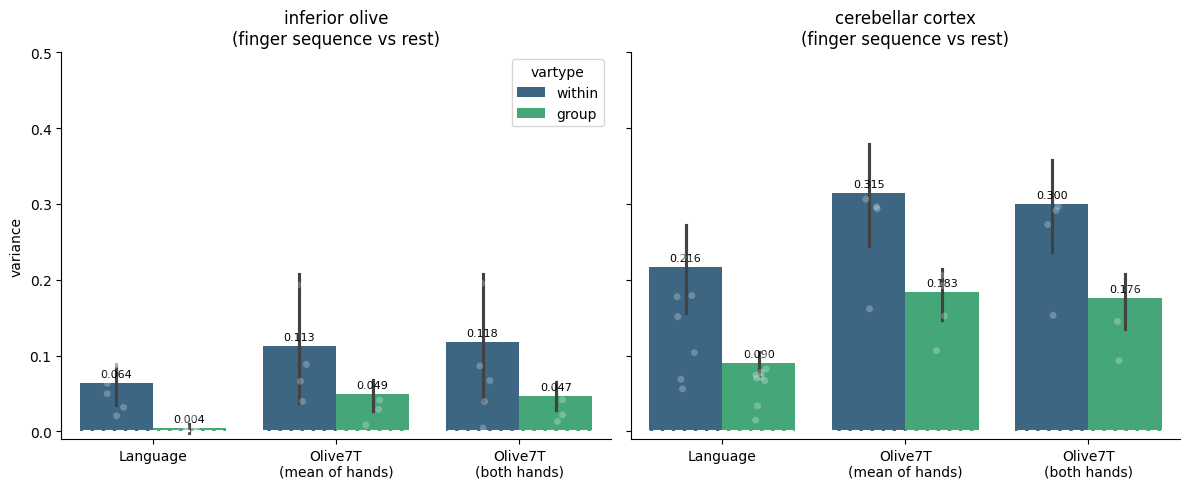

In [45]:
#finger sequence vs rest: Language vs Olive7T (mean of hands) vs Olive7T (both hands), olive and cerebellar cortex

pal = [[1,1,1], [1,1,1]] #for black bgd

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import Functional_Fusion.dataset as ds
from Functional_Fusion.reliability import decompose_subj_group

base_dir = '/Volumes/diedrichsen_data$/data/FunctionalFusion_new'
atlases = {'MNISymOlive1': 'inferior olive',
           'MNISymCereb2': 'cerebellar cortex'}          # atlas: panel title
hands = {'right': [1, 2, 3, 4, 13, 14, 15, 16],
         'left':  [5, 6, 7, 8, 9, 10, 11, 12]}
pairs = {                      # common label: (Olive7T name, Language name)
    #'action observation': ('action_observation', 'actobserv'),
    #'demand grid':        ('demand_grid_easy_diff', 'dmndgrid'),
    #'movie':              ('movie', 'movie'),
    'rest':               ('rest', 'rest'),
    #'spatial navigation': ('spatial_navigation', 'spatialnav'),
    #'verb generation':    ('verb_generation', 'vrbgen'),
    'finger sequence':    ('finger_sequence_surprise', 'fingr'),
}
task_set = 'finger sequence vs rest'     # goes into the titles
olive_tasks = [v[0] for v in pairs.values()]
lang_tasks = [v[1] for v in pairs.values()]


def decompose(data, info, keep, part_col):
    """Subject-wise decomposition on the selected rows -> shares per subject"""
    cond_vec = pd.factorize(info.task_code[keep])[0] + 1
    part_vec = info[part_col].values[keep]
    print("TEST", data[:, keep].shape, len(np.unique(cond_vec)), 'tasks,',
          len(np.unique(part_vec)), 'partitions')
    v = decompose_subj_group(data[:, keep, :], cond_vec, part_vec,
                             separate='subject_wise', subtract_mean=True)
    return v / v.sum(axis=1, keepdims=True)


olive = ds.DataSetNative(base_dir + '/Olive')
lang = ds.get_dataset_class(base_dir, 'Language')
subj_o = olive.get_participants().participant_id.tolist()
subj_l = lang.get_participants().participant_id.tolist()

rows = []
for atlas in atlases:
    print('----', atlas)
    # ---- load both datasets ----
    data_o, info_o = olive.get_data(space=atlas, ses_id='ses-s1', type='CondRun')
    data_l, info_l = lang.get_data(space=atlas, ses_id='ses-localizerfm', type='CondRun')
    print('Olive7T empty rows per subject:', np.isnan(data_o).any(axis=2).sum(axis=1))
    print('Language empty rows per subject:', np.isnan(data_l).any(axis=2).sum(axis=1))

    # ---- empty voxels ----
    valid = ~np.isnan(data_o).any(axis=(0, 1)) & ~np.isnan(data_l).any(axis=(0, 1))
    print(valid.sum(), 'of', len(valid), 'voxels kept')
    data_o = data_o[:, :, valid]
    data_l = data_l[:, :, valid]

    # ---- Olive7T: shared tasks ----
    shared_o = info_o.task_code.isin(olive_tasks).values
    # mean of hands: each hand separately, then averaged
    v_mean = np.mean([decompose(data_o, info_o, shared_o & info_o.run.isin(runs).values, 'run')
                      for runs in hands.values()], axis=0)
    # both hands: all 16 runs in one decomposition
    v_both = decompose(data_o, info_o, shared_o, 'run')

    for label, V in [('Olive7T mean', v_mean), ('Olive7T both', v_both)]:
        for s, v in zip(subj_o, V):
            rows.append({'atlas': atlas, 'dataset': label, 'subj_id': s,
                         'group': v[0], 'individual': v[1], 'noise': v[2]})

    # ---- Language: shared tasks ----
    shared_l = info_l.task_code.isin(lang_tasks).values
    for s, v in zip(subj_l, decompose(data_l, info_l, shared_l, 'run')):
        rows.append({'atlas': atlas, 'dataset': 'Language', 'subj_id': s,
                     'group': v[0], 'individual': v[1], 'noise': v[2]})

D_sh = pd.DataFrame(rows)
D_sh['within'] = D_sh.group + D_sh.individual
T_sh = D_sh.melt(id_vars=['dataset', 'atlas', 'subj_id'],
                 value_vars=['group', 'within'],
                 var_name='vartype', value_name='variance')

# ---- plot: one panel per atlas ----
order = ['Language', 'Olive7T mean', 'Olive7T both']
tick_labels = ['Language', 'Olive7T\n(mean of hands)', 'Olive7T\n(both hands)']

fig, axes = plt.subplots(1, len(atlases), figsize=(6 * len(atlases), 5), sharey=True)
for ax, (atlas, title) in zip(np.atleast_1d(axes), atlases.items()):
    X = T_sh[T_sh.atlas == atlas]
    sns.barplot(data=X, x='dataset', y='variance', hue='vartype',
                order=order,
                hue_order=['within', 'group'], palette='viridis', ax=ax)
    for c in ax.containers:
        ax.bar_label(c, fmt='%.3f', fontsize=8, padding=3)
    sns.stripplot(data=X, x='dataset', y='variance', hue='vartype',
                  order=order,
                  hue_order=['within', 'group'],
                  palette=pal, alpha=0.25, jitter=0.1,
                  dodge=True, legend=False, ax=ax)
    ax.axhline(0, color='white', linestyle='--')
    ax.set_ylim(-0.01, 0.5)
    ax.set_title(f'{title}\n({task_set})')
    ax.set_xlabel('')
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(tick_labels)
    if ax is not np.atleast_1d(axes)[0] and ax.get_legend() is not None:
        ax.get_legend().remove()            # keep the legend only in the first panel

plt.tight_layout()
plt.show()

In [12]:
#check old extraction vs new extraction.. 

import numpy as np
import pandas as pd
import Functional_Fusion.dataset as ds
from Functional_Fusion.reliability import flat2ndarray

base_dir = '/Volumes/diedrichsen_data$/data/FunctionalFusion_new'
wk_dir = '/Volumes/diedrichsen_data$/data/Cerebellum/Pontine7T/RegionOfInterest_BOLDMNI/data/group'
atlas = 'MNISymOlive1'
old = np.load(wk_dir + '/Lang_olive.npy')        # use the file name you saved for this atlas

lang = ds.get_dataset_class(base_dir, 'Language')
data_l, info_l = lang.get_data(space=atlas, ses_id='ses-localizerfm', type='CondRun')
labels = (info_l.task_code.astype(str) + '_' + info_l.cond_code.astype(str)).values
cond_vec = pd.factorize(labels)[0] + 1
new = flat2ndarray(np.nan_to_num(data_l), info_l.run.values, cond_vec)   # subjects x runs x conditions x voxels

print('old shape:', old.shape)
print('new shape:', new.shape)

old0 = np.nan_to_num(old)
print('largest difference:', np.max(np.abs(old0 - new)))
print('correlation:', np.corrcoef(old0.ravel(), new.ravel())[0, 1])

S, P, C, V = old0.shape
oldm = old0.mean(axis=1)            # subjects x conditions x voxels (averaged over runs)
newm = new.mean(axis=1)

# subjects: does old subject i look most like new subject i?
cs = np.corrcoef(oldm.reshape(S, -1), newm.reshape(S, -1))[:S, S:]
print('subject match (best new subject for each old subject):', cs.argmax(axis=1))
print('diagonal correlations:', np.round(np.diag(cs), 2))

# conditions: which new condition looks most like each old condition (group average)
cc = np.corrcoef(oldm.mean(0), newm.mean(0))[:C, C:]
print('condition match (best new condition for each old condition):', cc.argmax(axis=1))
print('best-match correlations:', np.round(cc.max(axis=1), 2))

old shape: (17, 8, 18, 1448)
new shape: (17, 8, 18, 1448)
largest difference: 3.2870177586649705
correlation: 0.5637784537285124
subject match (best new subject for each old subject): [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16]
diagonal correlations: [0.81 0.81 0.59 0.81 0.64 0.68 0.65 0.56 0.65 0.61 0.48 0.75 0.6  0.55
 0.68 0.71 0.76]
condition match (best new condition for each old condition): [ 0  0  1  2  3  5  6  7  8  9 10 11 12 13 14 15 16 17]
best-match correlations: [0.59 0.57 0.63 0.76 0.72 0.72 0.62 0.95 0.68 0.54 0.79 0.66 0.52 0.42
 0.72 0.71 0.64 0.67]
